In [1]:
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

---

## Vorverarbeitung der Daten

In [2]:
df = pd.read_csv("data.csv")
df["date"] = pd.to_datetime(df["DateTime"])

# Tarife werden vorerst zusammengelegt, "date" wird dabei als Index übernommen
df = df.groupby("date").agg({"KWH": "sum", "meters": "sum"})

# Normalisierung: Stromverbrauch eines Verbrauchers für jeden Zeitpunkt
df["kwh"] = df["KWH"] / df["meters"]

df = df[["KWH", "kwh", "meters"]]
df

,KWH,kwh,meters
date,,,
2011-11-23 09:00:00,0.569000,0.284500,2
2011-11-23 09:30:00,0.561000,0.280500,2
2011-11-23 10:00:00,0.920000,0.153333,6
2011-11-23 10:30:00,0.588000,0.098000,6
2011-11-23 11:00:00,0.772000,0.110286,7
...,...,...,...
2014-02-27 22:00:00,1494.603000,0.299760,4986
2014-02-27 22:30:00,1422.109001,0.285163,4987
2014-02-27 23:00:00,1258.090000,0.252274,4987


---

## Datenbereinigung

Im Datensatz sind fehlerhaft Datenpunkte enthalten, bei denen kein Verbraucher geschaltet ist und die Messungen außerhalb dem 30-Minuten-Taktes liegen.

In [3]:
# Prüfung auf Datenpunkte mit keinem Verbrauch
display(df.loc[(df["KWH"] == 0)])

# Falls die Prüfungen nichts zurückliefern, können die fehlerhaften Datenpunkte entfernt werden
# Prüfung auf korrekte Datenpunkte mit keinem Verbrauch
display(df.loc[(df["KWH"] == 0) & ((df.index.minute % 30 == 0) & (df.index.second == 0))])
# Prüfung auf korrekte Datenpunkte außerhalb des 30-Minuten-Taktes
display(df.loc[~(df["KWH"] == 0) & ~((df.index.minute % 30 == 0) & (df.index.second == 0))])

# Durch .asfreq() fallen die fehlerhaften Datenpunkte weg
df = df.sort_index().asfreq("30min")
df["kwh"].isna().sum()

,KWH,kwh,meters
date,,,
2012-12-18 15:13:26,0.0,NaN,0
2012-12-18 15:13:27,0.0,NaN,0
2012-12-18 15:13:28,0.0,NaN,0
2012-12-18 15:13:29,0.0,NaN,0
2012-12-18 15:13:30,0.0,NaN,0
...,...,...,...
2013-07-05 12:54:31,0.0,NaN,0
2013-07-05 13:15:05,0.0,NaN,0
2013-09-20 18:24:09,0.0,NaN,0


,KWH,kwh,meters
date,,,


,KWH,kwh,meters
date,,,


np.int64(0)

---

## Untersuchung der Zeitreihe auf Trend, Saisonalität und Residuum

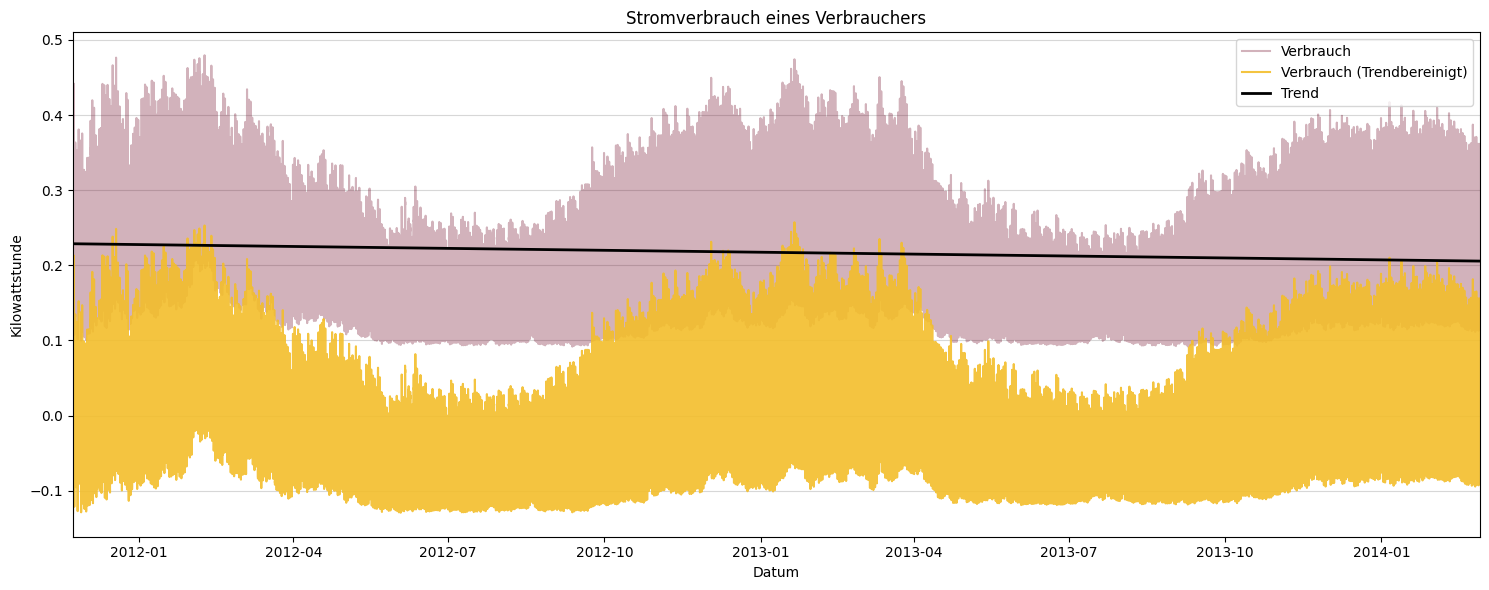

In [4]:
def analyse_trend(df: pd.DataFrame) -> pd.DataFrame:
    # Berechnung des linearen Trends der Zeitreihe
    x = mdates.date2num(df.index)
    p = np.poly1d(np.polyfit(x, df["kwh"], 1))
    df["kwh_trend"] = p(x)

    # Der Stromverbrauch bereinigt vom Trend
    df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]

    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.3, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.9, label="Verbrauch (Trendbereinigt)")
    ax.plot(df.index, df["kwh_trend"], color="#000000", alpha=1, linewidth=2, label="Trend")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    return df


df = analyse_trend(df)

<font color="orange">
Erkenntnisse: Es ist ein schwach fallender Trend zu erkennen - Stromverbrauch nimmt über die Zeit ab (auch, wenn man als Zeitraum volle Jahre nimmt, also vom 01.01.2012 bis 01.01.2014).
</font>

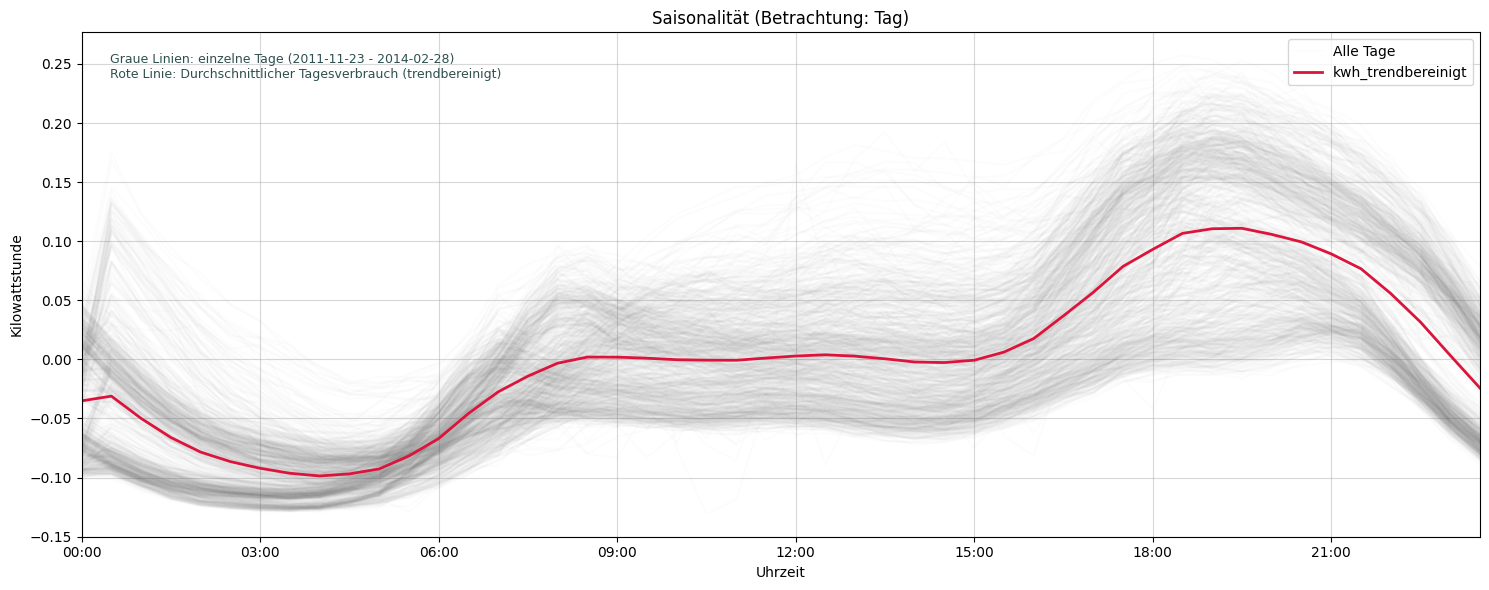

In [5]:
def analyse_seasonality(df: pd.DataFrame) -> pd.DataFrame:
    df["focus"] = df.index.hour * 2 + (df.index.minute // 30)  # Fokus auf einen Tag setzen

    # Der Mittelwert aller 30-Minuten Intervalle eines Tages
    seasonal = df.groupby("focus")["kwh_trendbereinigt"].mean()

    _, ax = plt.subplots(figsize=(15, 6))

    # Verbrauch aller Tage zur Veranschaulichung
    df["pivot_date"] = df.index.date  # Pivot arbeitet effizienter als die for-Schleife, die Logik ist aber die selbe
    pivot_data = df.pivot_table(index="focus", columns="pivot_date", values="kwh_trendbereinigt")

    lines = ax.plot(pivot_data, color="gray", alpha=0.02)
    if lines:
        lines[0].set_label("Alle Tage")

    seasonal.plot(ax=ax, color="crimson", linewidth=2)
    ax.set(
        title="Saisonalität (Betrachtung: Tag)",
        xlabel="Uhrzeit",
        ylabel="Kilowattstunde",
    )

    ax.text(
        0.02,
        0.96,
        f"Graue Linien: einzelne Tage ({pivot_data.columns.min()} - {pivot_data.columns.max()})\nRote Linie: Durchschnittlicher Tagesverbrauch (trendbereinigt)",
        transform=ax.transAxes,
        fontsize=9,
        color="darkslategray",
        verticalalignment="top",
    )

    ax.set_xticks(range(0, 48, 6))
    ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 3)])
    ax.grid(axis="both", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # .transform berechnet den Mittelwert pro Gruppe und weist ihn jedem Datenpunkt der Gruppe zu
    df["kwh_trendbereinigt_saison"] = df.groupby("focus")["kwh_trendbereinigt"].transform("mean")
    return df.drop(columns=["focus", "pivot_date"])


df = analyse_seasonality(df)

<font color="orange">
Erkenntnisse: Wie erwartet fällt der Stromverbrauch nachts sehr stark, nimmt im Laufe des Mittags zu und erreicht seinen Höhepunkt abends, wenn jeder wieder zu Hause ist.
</font>

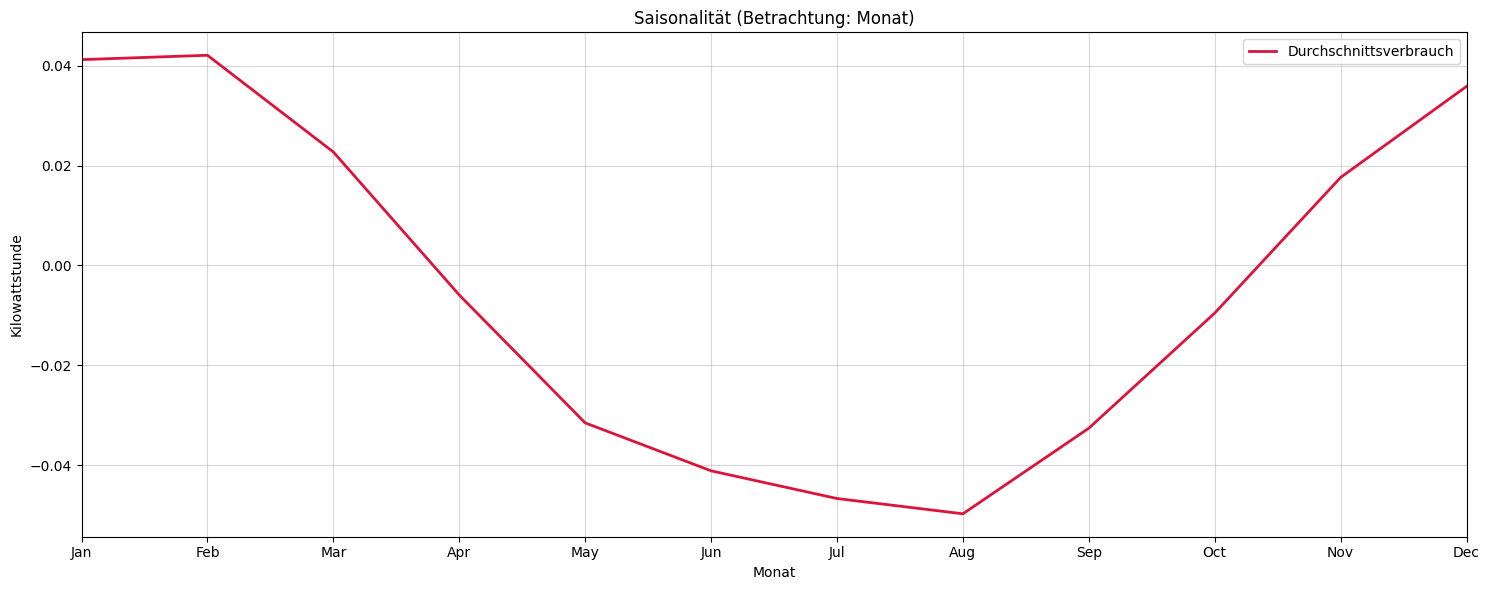

In [6]:
# Ergänzend
def analyse_seasonality_year(df: pd.DataFrame) -> None:
    df_year = df.copy()

    # Fokus auf ein Jahr setzen
    df_year["focus"] = df_year.index.month

    seasonal = df_year.groupby("focus")["kwh_trendbereinigt"].mean()

    _, ax = plt.subplots(figsize=(15, 6))

    seasonal.plot(ax=ax, color="crimson", alpha=1, label="Durchschnittsverbrauch", linewidth=2)  ##031E81 Ursprüngliche Farbe
    ax.set(
        title="Saisonalität (Betrachtung: Monat)",
        xlabel="Monat",
        ylabel="Kilowattstunde",
    )
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(pd.Series(range(1, 13)).map(lambda x: pd.to_datetime(x, format="%m").strftime("%b")))
    ax.grid(axis="both", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()


analyse_seasonality_year(df)

<font color="orange">
Erkenntnisse: Im den Wintermonaten wird deutlich mehr Strom verbraucht als im Sommer.
</font>

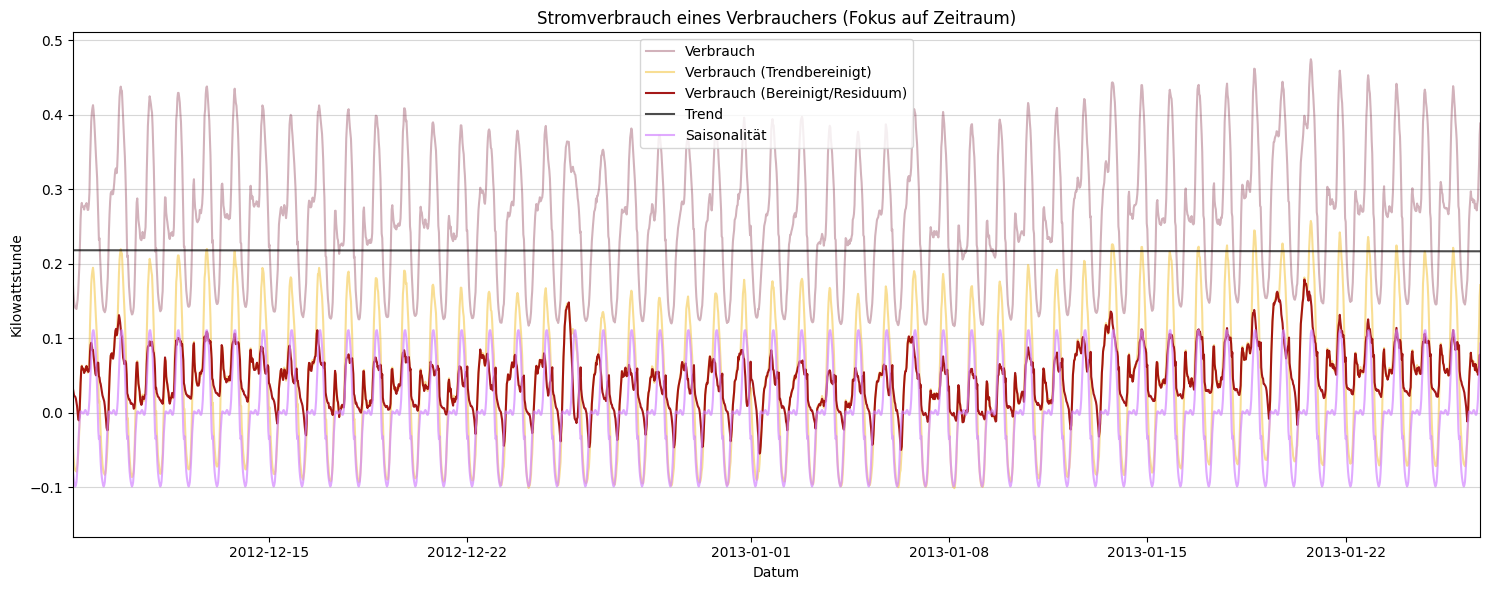

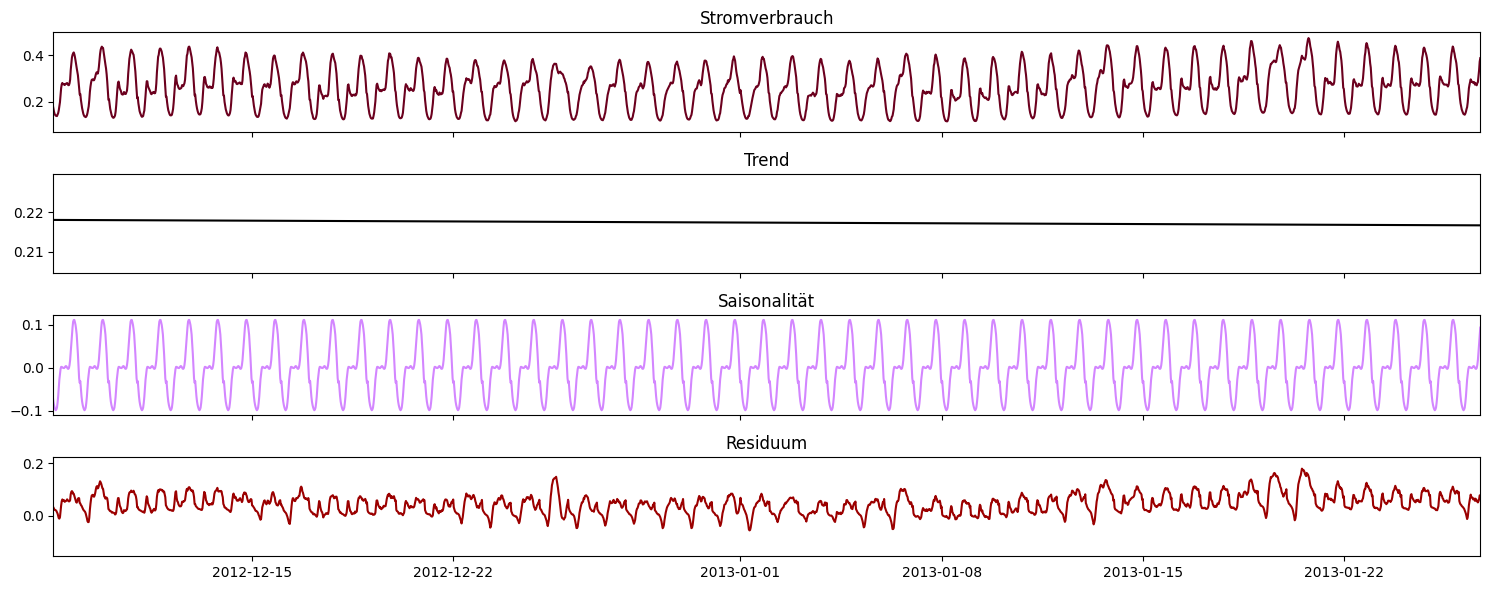

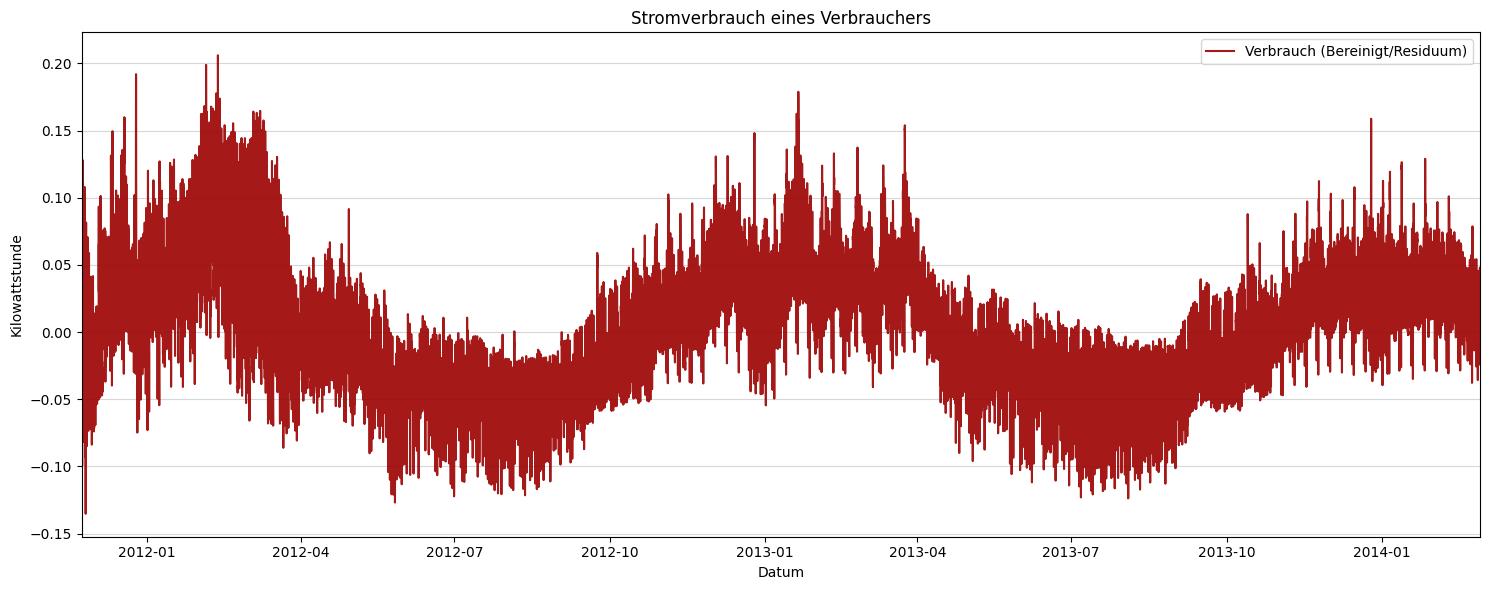

In [7]:
def analyse_cleaned(df: pd.DataFrame) -> pd.DataFrame:
    _, ax = plt.subplots(figsize=(15, 6))

    # Berechnung der bereinigte Zeitreihe bzw. dem Residuum/Rest
    df["kwh_bereinigt"] = df["kwh_trendbereinigt"] - df["kwh_trendbereinigt_saison"]

    ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.3, label="Verbrauch")
    ax.plot(df.index, df["kwh_trendbereinigt"], color="#F3BE2B", alpha=0.5, label="Verbrauch (Trendbereinigt)")
    ax.plot(df.index, df["kwh_bereinigt"], color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    ax.plot(df.index, df["kwh_trend"], color="#000000FF", alpha=0.7, label="Trend")
    ax.plot(df.index, df["kwh_trendbereinigt_saison"], color="#D386FF", alpha=0.7, label="Saisonalität")
    ax.set(
        title="Stromverbrauch eines Verbrauchers (Fokus auf Zeitraum)",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    # Begrenzung auf Zeitraum zur besseren Lesbarkeit
    ax.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    # Getrennte Plots
    _, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.46), pd.Series(df.index).quantile(0.52))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(df["kwh_trend"], color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(df["kwh_trendbereinigt_saison"], color="#D386FF")
    ax[2].set_title("Saisonalität")

    ax[3].plot(df["kwh_bereinigt"], color="#9B0000")
    ax[3].set_title("Residuum")

    plt.tight_layout()
    plt.show()

    # Residuum der gesamten Zeitreihe
    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(df.index, df["kwh_bereinigt"], color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()
    return df


df = analyse_cleaned(df)

---

## Verwendung von STL

Unsere manuelle Zerlegung basiert auf einem einfachen additiven Modell, welches einige Ungenauigkeiten aufweist: Ein linearer Trend ist unzureichend und eine einmalige Tages-Mittelung erfasst keine Schwankungen in der Saisonalität über die Zeit.

STL verwendet einen iterativen Prozess, der Trend und Saisonalität wechselseitig verfeinert. Die Loess-Glättung ist dabei robuster gegenüber Ausreißern, und die Saisonalitätskomponente kann sich über den Beobachtungszeitraum hinweg verändern. 

Das Residuum ist dadurch sauberer isoliert und repräsentiert tatsächlich nur den zufälligen Rest.

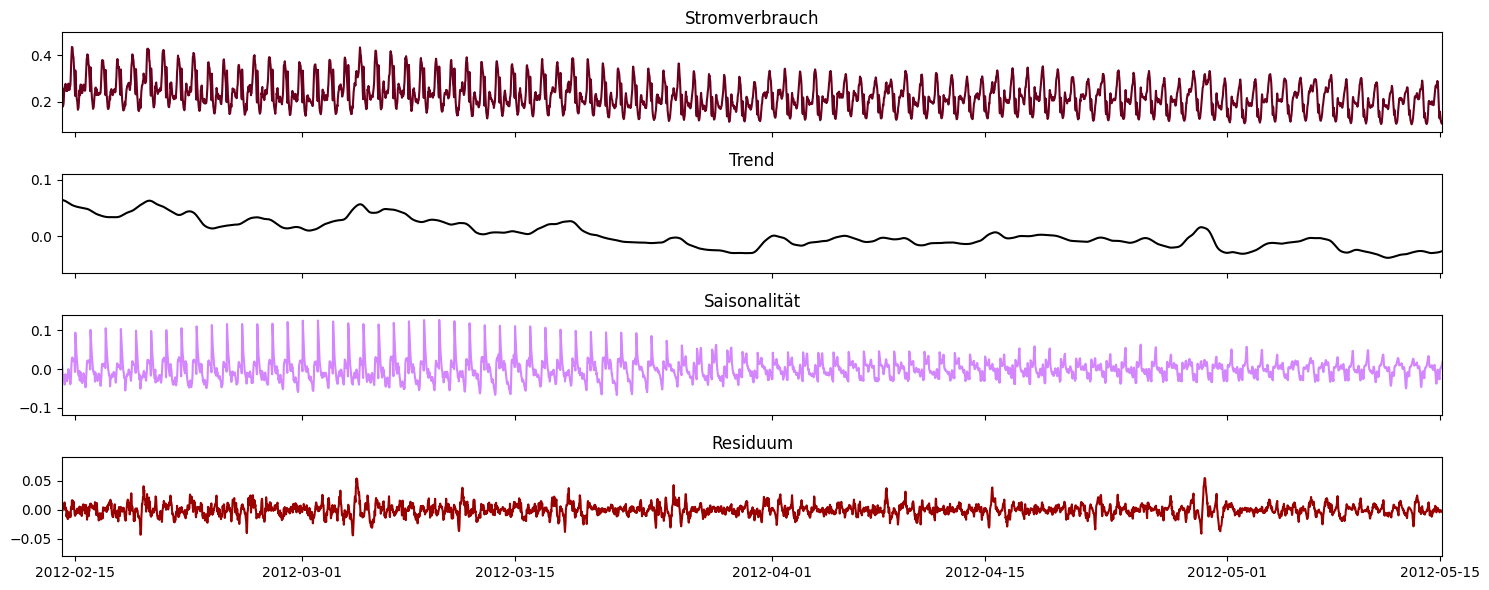

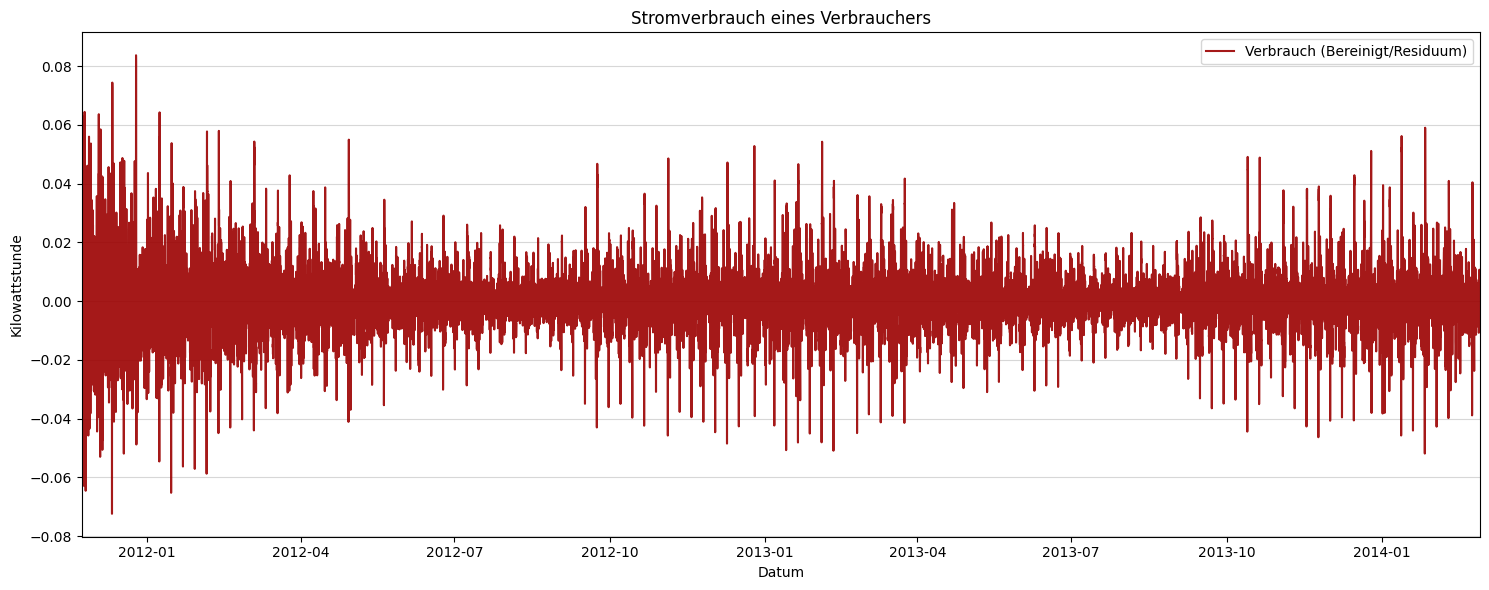

In [8]:
from statsmodels.tsa.seasonal import STL


def plot_STL(df: pd.DataFrame) -> pd.DataFrame:
    decomposition = STL(
        df["kwh_bereinigt"],
        period=48,
    )
    decomposition = decomposition.fit()

    _, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.10), pd.Series(df.index).quantile(0.21))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(decomposition.trend, color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(decomposition.seasonal, color="#D386FF")
    ax[2].set_title("Saisonalität")

    ax[3].plot(decomposition.resid, color="#9B0000")
    ax[3].set_title("Residuum")

    plt.tight_layout()
    plt.show()

    # Residuum der gesamten Zeitreihe
    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(df.index, decomposition.resid, color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    ax.set(
        title="Stromverbrauch eines Verbrauchers",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()

    return decomposition


decomposition = plot_STL(df)

In [9]:
# Im Folgendem verwenden wir die berechneten Werte der STL-Methode
df["kwh_trend"] = decomposition.trend
df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]
df["kwh_trendbereinigt_saison"] = decomposition.seasonal
df["kwh_bereinigt"] = decomposition.resid

In [10]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(df["kwh_bereinigt"], order=(1, 0, 1))
result = model.fit()

final_residuals = result.resid

<Axes: xlabel='date'>

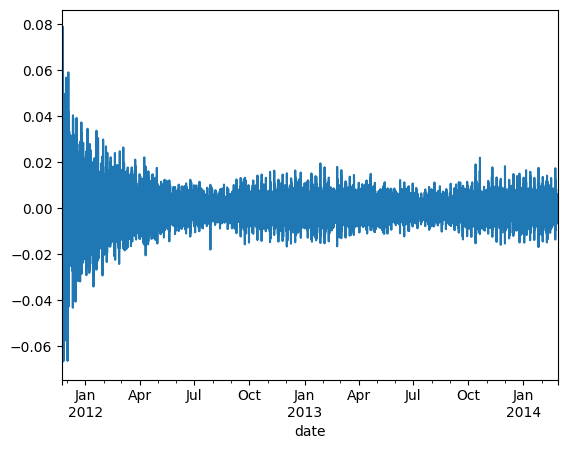

In [11]:
final_residuals.plot()

---

## Autokorrelation und Partielle Autokorrelation

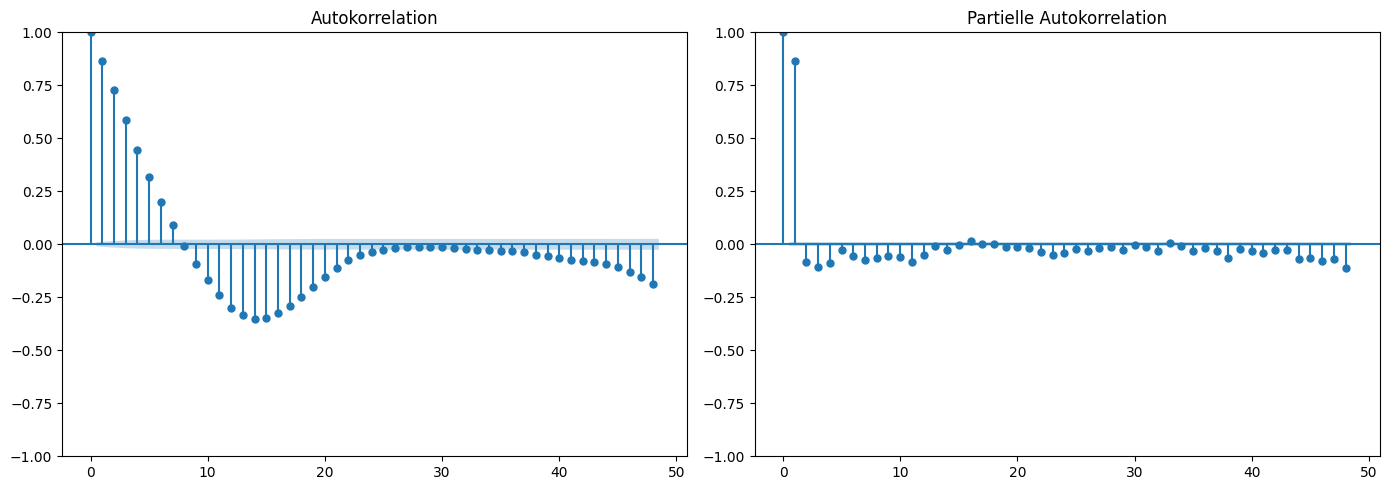

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

_, ax = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(df["kwh_bereinigt"], lags=48, ax=ax[0])
ax[0].set_title("Autokorrelation")

plot_pacf(df["kwh_bereinigt"], lags=48, ax=ax[1])
ax[1].set_title("Partielle Autokorrelation")

plt.tight_layout()
plt.show()

<font color="orange">
Erkenntnisse: Es handelt sich dabei um eine Abhängigkeit jedes Lag auf den vorherigen, wie durch die PACF bestätigt. 
Das Echo der Autokorrelation lässt sich als AR(1)-Prozess erklären, jeder Lag ist von seinem vorherigen abhängig.
</font>


---

## Vertiefung: Woher kommt die negative Autokorrelation der Residuen bei Lag 12–15?

In der ACF oben (Zelle *Autokorrelation*) fällt eine ausgeprägte negative Senke bei den Lags 12–15 (≈ 6–7,5 h) auf. Im Folgenden wird systematisch geklärt, **wie** dieses Muster zustande kommt. Wir gehen in drei Schritten vor:

1. **Kontrolle Vorverarbeitung** – hängt die Signatur an der (doppelten) Zerlegung?
2. **Kontrolle STL/Filter** – erzeugt STL die Senke aus strukturlosem Input (Slutsky-Yule)?
3. **Physikalische Ursache** – welche reale Tagesdynamik trägt die Senke, und lässt sie sich entfernen?

### Kontrolle 1 — einfache vs. doppelte Zerlegung

Im Notebook läuft STL nicht auf den Rohdaten, sondern auf dem bereits manuell trend- und saisonbereinigten Residuum (doppelte Zerlegung). Wir prüfen, ob die Signatur daran hängt, indem wir drei Wege vergleichen, das Residuum zu gewinnen.

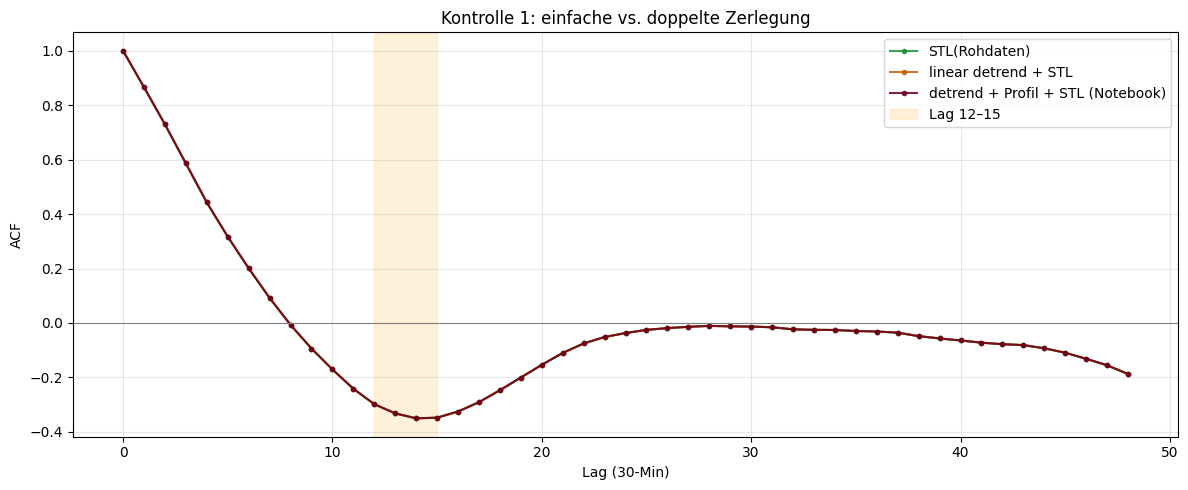

STL(roh)     Trog @ Lag 14  =  -0.350
detrend+STL  Trog @ Lag 14  =  -0.350
Notebook     Trog @ Lag 14  =  -0.350


In [13]:
# Hilfsfunktionen für die folgende Analyse
from statsmodels.tsa.stattools import acf

LAGS = 48

def acf_trough(a):
    """Tiefster Punkt der ACF ab Lag 1 -> (Lag, Wert)."""
    k = int(np.argmin(a[1:])) + 1
    return k, float(a[k])

# Drei Wege zum Tages-Residuum
x = mdates.date2num(df.index)
p_lin = np.poly1d(np.polyfit(x, df["kwh"], 1))
detrended = df["kwh"] - p_lin(x)
slot = pd.Series(df.index.hour * 2 + (df.index.minute // 30), index=df.index)
profil_global = detrended.groupby(slot).transform("mean")
manuell_resid = detrended - profil_global            # = Input, auf den im Notebook STL läuft

resid_S1 = STL(df["kwh"],     period=48).fit().resid  # STL direkt auf Rohdaten
resid_S2 = STL(detrended,     period=48).fit().resid  # linear detrend -> STL
resid_S3 = STL(manuell_resid, period=48).fit().resid  # detrend + Profil -> STL (Notebook)

fig, ax = plt.subplots(figsize=(12, 5))
for r, lab, c in [(resid_S1, "STL(Rohdaten)", "#1A8F3D"),
                  (resid_S2, "linear detrend + STL", "#C45E00"),
                  (resid_S3, "detrend + Profil + STL (Notebook)", "#6B001E")]:
    ax.plot(range(LAGS + 1), acf(r.dropna(), nlags=LAGS), marker="o", ms=3, label=lab, color=c, alpha=0.85)
ax.axhline(0, color="gray", lw=0.8)
ax.axvspan(12, 15, color="orange", alpha=0.15, label="Lag 12–15")
ax.set(title="Kontrolle 1: einfache vs. doppelte Zerlegung", xlabel="Lag (30-Min)", ylabel="ACF")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for r, lab in [(resid_S1, "STL(roh)   "), (resid_S2, "detrend+STL"), (resid_S3, "Notebook   ")]:
    k, v = acf_trough(acf(r.dropna(), nlags=LAGS))
    print(f"{lab}  Trog @ Lag {k:>2}  =  {v:+.3f}")

<font color="orange">
Erkenntnisse: Alle drei Kurven liegen exakt aufeinander (Trog @ Lag 14, −0,35). Die Signatur hängt also nicht an der doppelten Zerlegung – es liegt kein Vorverarbeitungsfehler vor. Dass andere Gruppen das Muster nicht sehen, dürfte an einer anderen Methode liegen (z. B. saisonale Differenzierung) oder daran, dass die ACF auf einer noch driftbehafteten Reihe berechnet wurde, in der die Senke vom langsamen Drift überdeckt wird.
</font>

### Kontrolle 2 — erzeugt STL die Senke aus strukturlosem Input? (Slutsky-Yule)

Glättungs- und Differenzfilter können einer Zeitreihe Schwingungen *aufprägen*, die im Original nicht enthalten sind (Slutsky-Yule-Effekt). Wir schicken deshalb weißes Rauschen und einen reinen AR(1)-Prozess (nur kurzfristige Persistenz, keine Periodik) durch STL und betrachten die ACF des Rests.

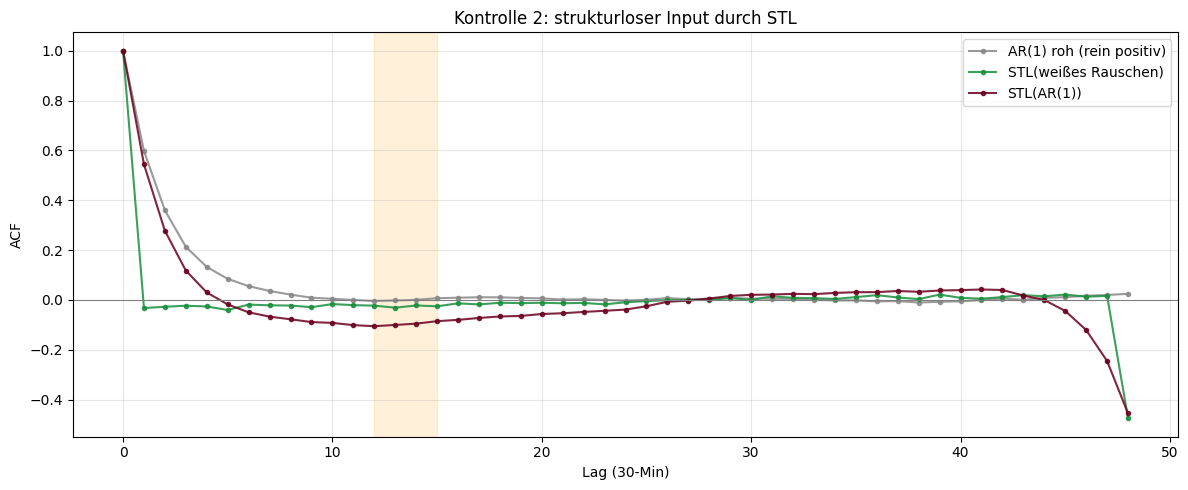

weißes Rauschen -> STL : (48, -0.4749891671054422)
AR(1)           -> STL : (48, -0.4553577483057399)


In [14]:
rng = np.random.default_rng(0)
n = len(df)
weiss = pd.Series(rng.standard_normal(n), index=df.index)

phi = 0.6                                   # AR(1): nur Persistenz, keine Periodik
ar = np.zeros(n); e = rng.standard_normal(n)
for t in range(1, n):
    ar[t] = phi * ar[t - 1] + e[t]
ar = pd.Series(ar, index=df.index)

resid_weiss = STL(weiss, period=48).fit().resid
resid_ar    = STL(ar,    period=48).fit().resid

fig, ax = plt.subplots(figsize=(12, 5))
for r, lab, c in [(ar,          "AR(1) roh (rein positiv)", "#888888"),
                  (resid_weiss, "STL(weißes Rauschen)",      "#1A8F3D"),
                  (resid_ar,    "STL(AR(1))",                "#6B001E")]:
    ax.plot(range(LAGS + 1), acf(r.dropna(), nlags=LAGS), marker="o", ms=3, label=lab, color=c, alpha=0.85)
ax.axhline(0, color="gray", lw=0.8)
ax.axvspan(12, 15, color="orange", alpha=0.15)
ax.set(title="Kontrolle 2: strukturloser Input durch STL", xlabel="Lag (30-Min)", ylabel="ACF")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("weißes Rauschen -> STL :", acf_trough(acf(resid_weiss.dropna(), nlags=LAGS)))
print("AR(1)           -> STL :", acf_trough(acf(resid_ar.dropna(),    nlags=LAGS)))

<font color="orange">
Erkenntnisse: Weißes Rauschen ergibt bei 12–15 nichts – nur einen scharfen Einbruch bei Lag 48 (STL schätzt auch aus Rauschen eine Periode-48-„Saison“ und zieht sie ab; das erklärt den leicht negativen Ausläufer bei ~48 in der echten ACF). Erst der persistente AR(1) erzeugt eine flache Senke (~−0,10) bei 12–14 – das ist der Slutsky-Yule-Anteil, der Persistenz braucht. Die echten Daten erreichen aber −0,35. Der kleine Filter-Anteil erklärt die Signatur also nicht; der Großteil muss aus realer Tagesstruktur stammen.
</font>

### Physikalische Ursache — wer treibt die Senke?

Wir untersuchen das STL-Residuum (`df["kwh_bereinigt"]`) bedingt nach Jahreszeit und Wochentag und lokalisieren anschließend, welche Tageszeiten die negative Korrelation bei Lag 14 tragen. Reagiert die Senke auf physikalische Bedingungen, ist sie kein Filter-Artefakt.

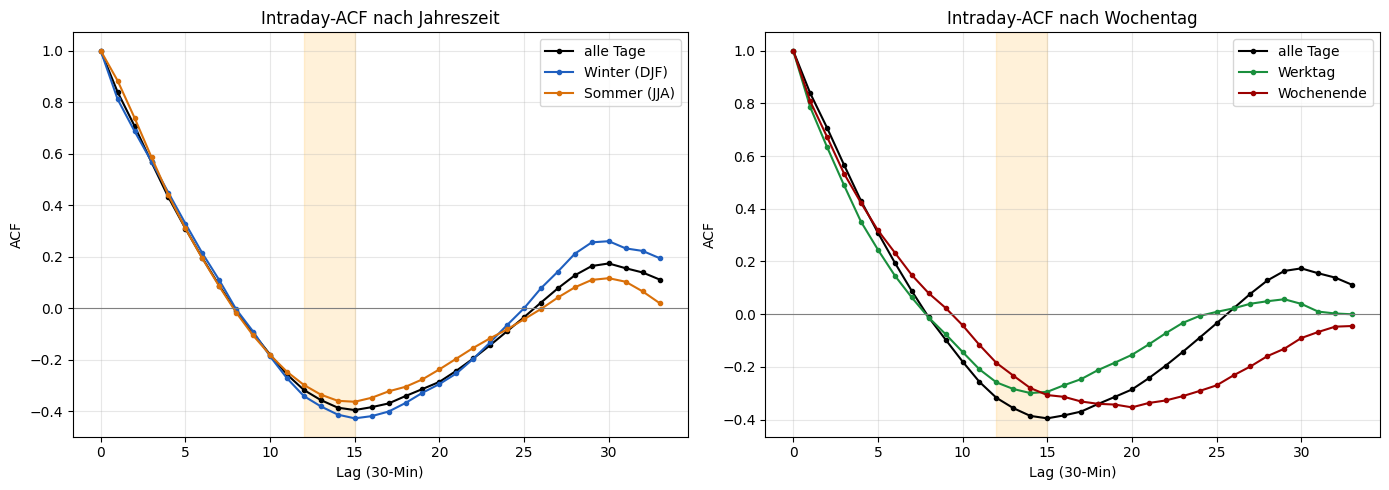

Trog  alle   : (15, -0.39542679801668)
Trog  Winter : (15, -0.4275883115969957)  Sommer: (15, -0.3632042631470768)
Trog  Werktag: (14, -0.29947144601317693)  WE    : (20, -0.3536847707738255)


In [15]:
# Tag x Slot Matrix des STL-Residuums (nur vollständige Tage)
work = pd.DataFrame({"resid": df["kwh_bereinigt"]})
work["slot"] = df.index.hour * 2 + (df.index.minute // 30)
work["day"]  = df.index.normalize()

piv = work.pivot_table(index="day", columns="slot", values="resid").dropna(axis=0)
months  = pd.DatetimeIndex(piv.index).month
is_wknd = pd.DatetimeIndex(piv.index).dayofweek >= 5
winter, sommer = piv[np.isin(months, [12, 1, 2])], piv[np.isin(months, [6, 7, 8])]
werktag, we    = piv[~is_wknd], piv[is_wknd]

def intraday_acf(M, maxlag=33):
    """Saumfreie Intraday-ACF: pro Lag Mittel der Cross-Day-Korrelation über die Slots."""
    out = [1.0]
    for l in range(1, maxlag + 1):
        out.append(np.mean([np.corrcoef(M.iloc[:, s], M.iloc[:, s + l])[0, 1]
                            for s in range(0, 48 - l)]))
    return np.array(out)

ML = 33
acf_alle, acf_w, acf_s = intraday_acf(piv), intraday_acf(winter), intraday_acf(sommer)
acf_wd, acf_we = intraday_acf(werktag), intraday_acf(we)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, lab, c in [(acf_alle, "alle Tage", "#000000"), (acf_w, "Winter (DJF)", "#1f5fbf"), (acf_s, "Sommer (JJA)", "#d9700a")]:
    ax[0].plot(range(ML + 1), a, marker="o", ms=3, label=lab, color=c)
ax[0].axhline(0, color="gray", lw=0.8); ax[0].axvspan(12, 15, color="orange", alpha=0.15)
ax[0].set(title="Intraday-ACF nach Jahreszeit", xlabel="Lag (30-Min)", ylabel="ACF"); ax[0].legend(); ax[0].grid(alpha=0.3)
for a, lab, c in [(acf_alle, "alle Tage", "#000000"), (acf_wd, "Werktag", "#1A8F3D"), (acf_we, "Wochenende", "#9B0000")]:
    ax[1].plot(range(ML + 1), a, marker="o", ms=3, label=lab, color=c)
ax[1].axhline(0, color="gray", lw=0.8); ax[1].axvspan(12, 15, color="orange", alpha=0.15)
ax[1].set(title="Intraday-ACF nach Wochentag", xlabel="Lag (30-Min)", ylabel="ACF"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("Trog  alle   :", acf_trough(acf_alle))
print("Trog  Winter :", acf_trough(acf_w), " Sommer:", acf_trough(acf_s))
print("Trog  Werktag:", acf_trough(acf_wd), " WE    :", acf_trough(acf_we))

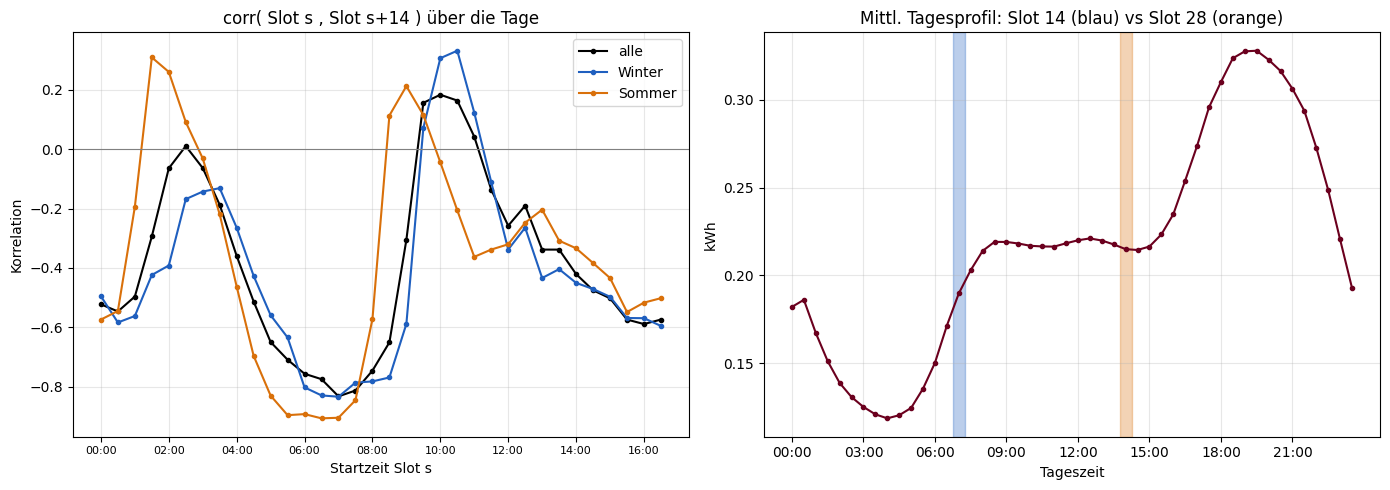

Stärkste Anti-Korrelation: 07:00  <->  14:00   r = -0.833


In [16]:
# Wer treibt Lag 14? Korrelation zwischen Slot s und Slot s+14 über die Tage.
L = 14
slots = np.arange(0, 48 - L)
slot_corr = lambda M: np.array([np.corrcoef(M.iloc[:, s], M.iloc[:, s + L])[0, 1] for s in slots])
sc_alle, sc_w, sc_s = slot_corr(piv), slot_corr(winter), slot_corr(sommer)
s_min = int(slots[np.argmin(sc_alle)])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for y, lab, c in [(sc_alle, "alle", "#000000"), (sc_w, "Winter", "#1f5fbf"), (sc_s, "Sommer", "#d9700a")]:
    ax[0].plot(slots, y, marker="o", ms=3, label=lab, color=c)
ax[0].axhline(0, color="gray", lw=0.8)
ax[0].set(title="corr( Slot s , Slot s+14 ) über die Tage", xlabel="Startzeit Slot s", ylabel="Korrelation")
ax[0].set_xticks(range(0, 34, 4)); ax[0].set_xticklabels([f"{s//2:02d}:{'30' if s%2 else '00'}" for s in range(0, 34, 4)], fontsize=8)
ax[0].legend(); ax[0].grid(alpha=0.3)

prof_kwh = df["kwh"].groupby(work["slot"]).mean()
ax[1].plot(prof_kwh.index, prof_kwh.values, color="#6B001E", marker="o", ms=3)
ax[1].axvspan(s_min - 0.5, s_min + 0.5, color="#1f5fbf", alpha=0.3)
ax[1].axvspan(s_min + L - 0.5, s_min + L + 0.5, color="#d9700a", alpha=0.3)
ax[1].set(title=f"Mittl. Tagesprofil: Slot {s_min} (blau) vs Slot {s_min + L} (orange)", xlabel="Tageszeit", ylabel="kWh")
ax[1].set_xticks(range(0, 48, 6)); ax[1].set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 3)])
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

t1 = f"{s_min//2:02d}:{'30' if s_min%2 else '00'}"
t2 = f"{(s_min+L)//2:02d}:{'30' if (s_min+L)%2 else '00'}"
print(f"Stärkste Anti-Korrelation: {t1}  <->  {t2}   r = {sc_alle.min():+.3f}")

<font color="orange">
Erkenntnisse: Die Senke reagiert klar auf physikalische Bedingungen und ist damit kein Artefakt: im Winter tiefer als im Sommer (heizgetrieben), und der Trog liegt am Werktag bei Lag 14 (≈7 h), am Wochenende erst bei ~Lag 20 (≈10 h) – der Rhythmus verschiebt sich. Die stärkste Anti-Korrelation besteht zwischen ~07:00 und ~14:00 (r ≈ −0,83): An Tagen mit überdurchschnittlichem Morgen ist der frühe Nachmittag unterdurchschnittlich und umgekehrt. Das ist eine intraday-Lastverschiebung (das Tagesvolumen bleibt grob erhalten, nur die Verteilung verschiebt sich), die STL erst sichtbar macht, indem es das mittlere Tagesprofil entfernt.
</font>

#### Anderer Blickwinkel: vollständige Slot-zu-Slot-Korrelationsmatrix

Statt nur Lag 14 zu betrachten, zeigt die volle 48×48-Korrelationsmatrix der Residuen (über die Tage) die Anti-Korrelation direkt als Block.

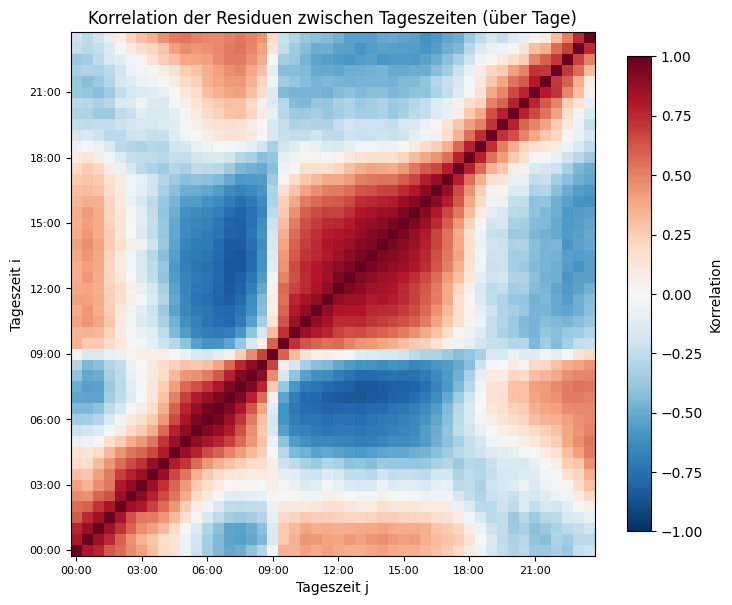

In [17]:
corr = np.corrcoef(piv.values.T)   # 48 x 48 Korrelationsmatrix der Tageszeit-Slots

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, origin="lower", cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(title="Korrelation der Residuen zwischen Tageszeiten (über Tage)", xlabel="Tageszeit j", ylabel="Tageszeit i")
ticks = range(0, 48, 6)
ax.set_xticks(ticks); ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 3)], fontsize=8)
ax.set_yticks(ticks); ax.set_yticklabels([f"{h:02d}:00" for h in range(0, 24, 3)], fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="Korrelation")
plt.tight_layout(); plt.show()

<font color="orange">
Erkenntnisse: Entlang der Diagonale (benachbarte Zeiten) ist die Korrelation positiv. Der auffällige blaue (negative) Block verbindet den frühen Vormittag (~06–08 Uhr) mit dem frühen Nachmittag (~13–15 Uhr) – genau die ~7-h-Wippe, die als negative Senke bei Lag 12–15 in der ACF erscheint.
</font>

### Verbesserung der Zerlegung — bedingte Tagesprofile (Saison × Wochentag)

Naheliegende Verbesserung: statt eines globalen Tagesprofils ein eigenes Profil je Saison und Wochentag-Typ abziehen. Das entfernt den Anteil der Signatur, der aus *Unterschieden zwischen* den Gruppen stammt. Wir messen, wie viel die Senke dadurch tatsächlich nachgibt.

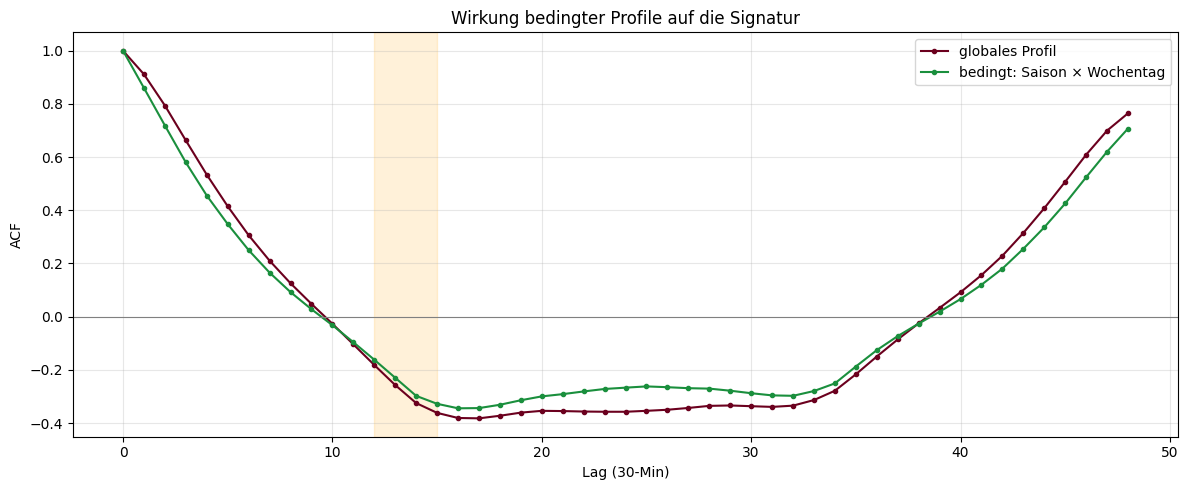

globales Profil : Trog @ Lag 17 = -0.382
bedingtes Profil: Trog @ Lag 16 = -0.345
Reduktion der Tiefe: +9.9 %


In [18]:
# Sauberer Trend auf den Rohdaten (df["kwh_trend"] ist hier der STL-Trend des
# manuellen Residuums, also ~0 - daher hier eigener STL-Trend auf der Rohreihe),
# dann globales vs. bedingtes Profil vergleichen.
trend_raw = STL(df["kwh"], period=48).fit().trend
detr_stl = df["kwh"] - trend_raw
slot = pd.Series(df.index.hour * 2 + (df.index.minute // 30), index=df.index)

m = df.index.month
season = pd.Series(np.select([np.isin(m, [12, 1, 2]), np.isin(m, [3, 4, 5]), np.isin(m, [6, 7, 8])],
                             ["Winter", "Fruehling", "Sommer"], default="Herbst"), index=df.index)
wtyp = pd.Series(np.where(df.index.dayofweek >= 5, "WE", "WT"), index=df.index)

prof_glob = detr_stl.groupby(slot).transform("mean")                       # ein globales Profil
key       = season + "|" + wtyp + "|" + slot.astype(str)
prof_cond = detr_stl.groupby(key).transform("mean")                        # Profil je Saison × Wochentag

resid_glob = detr_stl - prof_glob
resid_cond = detr_stl - prof_cond

fig, ax = plt.subplots(figsize=(12, 5))
for r, lab, c in [(resid_glob, "globales Profil", "#6B001E"),
                  (resid_cond, "bedingt: Saison × Wochentag", "#1A8F3D")]:
    ax.plot(range(LAGS + 1), acf(r.dropna(), nlags=LAGS), marker="o", ms=3, label=lab, color=c)
ax.axhline(0, color="gray", lw=0.8); ax.axvspan(12, 15, color="orange", alpha=0.15)
ax.set(title="Wirkung bedingter Profile auf die Signatur", xlabel="Lag (30-Min)", ylabel="ACF")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

kg, vg = acf_trough(acf(resid_glob.dropna(), nlags=LAGS))
kc, vc = acf_trough(acf(resid_cond.dropna(), nlags=LAGS))
print(f"globales Profil : Trog @ Lag {kg} = {vg:+.3f}")
print(f"bedingtes Profil: Trog @ Lag {kc} = {vc:+.3f}")
print(f"Reduktion der Tiefe: {(1 - vc / vg) * 100:+.1f} %")

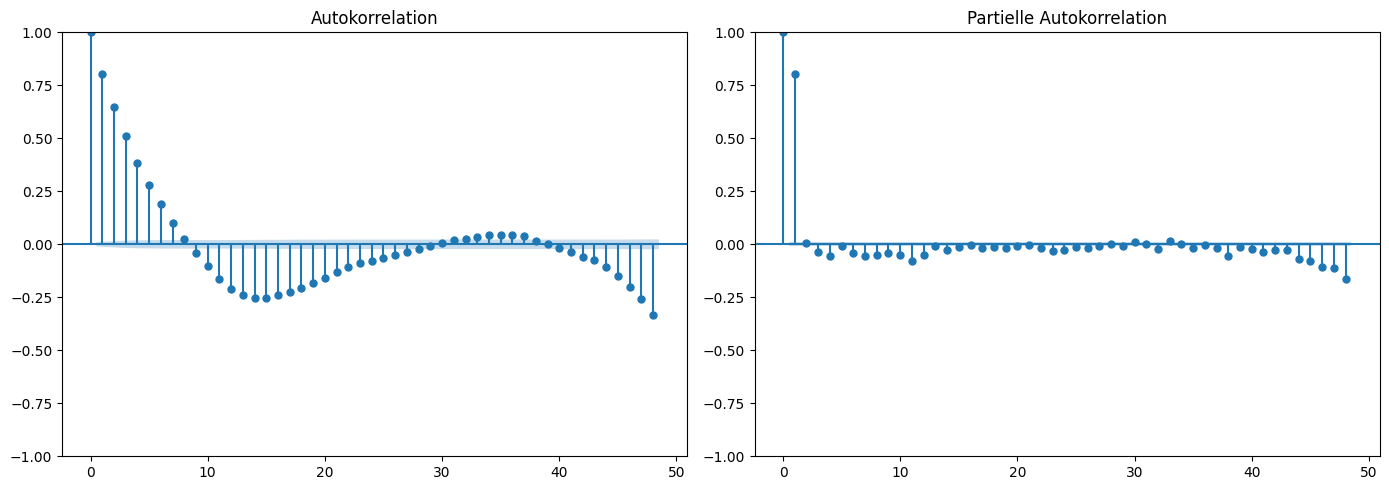

In [31]:
# Bedingtes Profil (Saison × Wochentag × Tageszeit) ZUSÄTZLICH von der
# bereits komplett bereinigten Reihe df["kwh_bereinigt"] (STL-Residuum) abziehen.
m = df.index.month
season = pd.Series(np.select(
    [np.isin(m, [12, 1, 2]), np.isin(m, [3, 4, 5]), np.isin(m, [6, 7, 8])],
    ["Winter", "Fruehling", "Sommer"], default="Herbst"), index=df.index)
wtyp = pd.Series(np.where(df.index.dayofweek >= 5, "WE", "WT"), index=df.index)
slot = pd.Series(df.index.hour * 2 + (df.index.minute // 30), index=df.index)

key = season + "|" + wtyp + "|" + slot.astype(str)
resid_cond = df["kwh_bereinigt"] - df["kwh_bereinigt"].groupby(key).transform("mean")

_, ax = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(resid_cond.dropna(), lags=48, ax=ax[0])
ax[0].set_title("Autokorrelation")
plot_pacf(resid_cond.dropna(), lags=48, ax=ax[1])
ax[1].set_title("Partielle Autokorrelation")
plt.tight_layout()
plt.show()

<font color="orange">
Erkenntnisse: Die bedingten Profile senken die Tiefe der Senke nur moderat (~10 %). Das bestätigt: der Großteil der Signatur ist keine Differenz *zwischen* den Gruppen, sondern eine *tagesindividuelle* Lastverschiebung – ihr Mittelwert ist ~0, sie lässt sich also durch kein (auch kein bedingtes) festes Profil wegsubtrahieren. Bedingte Profile lohnen sich dennoch zur saubereren Bereinigung des deterministischen Teils; die Lastverschiebung selbst bleibt bewusst im Residuum, weil sie vorhersagbares Signal ist.
</font>

### Fazit

Die negative Autokorrelation bei Lag 12–15 ist eine **Kombination**:

- **Kein** Vorverarbeitungsfehler (einfache und doppelte Zerlegung liefern identische ACF).
- Ein **kleiner Filter-Anteil** (~−0,10, Slutsky-Yule auf der Persistenz) plus ein separater **Lag-48-Ausläufer** aus der STL-Saisonschätzung.
- Der **Hauptteil** ist eine reale **Morgen↔Nachmittag-Lastverschiebung** (~7 h, stärkste Anti-Korrelation 07:00↔14:00, r ≈ −0,83), im Winter stärker, am Wochenende zeitlich verschoben. STL macht sie sichtbar, indem es Trend und mittleres Tagesprofil entfernt.

**Entfernen?** Nicht durch Abziehen einer weiteren festen oder bedingten Periode – es ist eine tagesindividuelle Umverteilung, kein fester Zyklus. Sie gehört nicht in die Zerlegung, sondern ins **Modell**: Die Anti-Korrelation bedeutet, dass der Morgenwert den frühen Nachmittag (negativ) vorhersagt – nutzbar als zusätzliches Lag-/Feature. Für die eigentliche 6-h-Prognose ist die Abhängigkeit bei Lag 12 ohnehin bereits schwach.

In [19]:
# Funktionen für die Modellanalyse
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from typing import Tuple


def plot_pred(test: pd.DataFrame, pred: np.ndarray, col: str) -> None:
    _, ax = plt.subplots(figsize=(15, 6))

    ax.plot(test.index, test[col], color="#6B001E", alpha=0.7, label="Tatsächlicher Verbrauch")
    ax.plot(test.index, pred, color="#0029BC", alpha=1, label="Prognose")

    ax.set(
        title="Prognose 6 Stunden in die Zukunft",
        xlabel="Datum",
        ylabel="Kilowattstunde",
    )
    ax.set_xlim(pd.Series(test.index).quantile(0.0), pd.Series(test.index).quantile(0.1))
    ax.grid(axis="y", alpha=0.5)
    ax.margins(x=0)
    ax.legend()

    plt.tight_layout()
    plt.show()


def show_metrics(y_test: np.ndarray, pred: np.ndarray, model: LinearRegression, verbose: bool = True) -> Tuple[float, float, float, float]:
    r2 = r2_score(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = root_mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)

    if verbose:
        print(
            f"Regression Intercept: {model.intercept_}\n"
            f"Regression Coefficients: {model.coef_}\n"
            f"R²:\t{r2: .6f}\n"
            f"MSE:\t{mse: .6f}\n"
            f"RMSE:\t{rmse: .6f}\n"
            f"MAE:\t{mae: .6f}\n"
        )

    return r2, mse, rmse, mae

---

## Vorhersage mit Linearer Regression

Zielvariable hier ist zunächst der tatsächliche Verbrauch 6 Stunden in der Zukunft.

Da STL für seine Decompesition auch Daten aus der Zukunft nimmt, würde die Weiterverwendung für das Training von Modellen Data Leakage einführen.

Deshalb werden für die Trainingsdaten wieder auf die manuelle Zerlegung zurückgegriffen.

In [20]:
df_model_a = df.copy()
# Aufteilung der Trainings- und Testdaten
split = int(len(df_model_a) * 0.7)
train = df_model_a.iloc[:split]
test = df_model_a.iloc[split:]

In [21]:
# Trend
x_train = mdates.date2num(train.index)
p = np.poly1d(np.polyfit(x_train, train["kwh"], 1))

train["kwh_trend"] = p(mdates.date2num(train.index))
test["kwh_trend"] = p(mdates.date2num(test.index))  # Extrapolation auf Testdaten

# Trendbereinigung
train["kwh_trendbereinigt"] = train["kwh"] - train["kwh_trend"]
test["kwh_trendbereinigt"] = test["kwh"] - test["kwh_trend"]


# Saisonalität
train["focus"] = train.index.hour * 2 + (train.index.minute // 30)
seasonal = train.groupby("focus")["kwh_trendbereinigt"].mean()  # Nur Train

test["focus"] = test.index.hour * 2 + (test.index.minute // 30)

train["kwh_saison"] = train["focus"].map(seasonal)
test["kwh_saison"] = test["focus"].map(seasonal)  # Mapping, kein Refit


# Residuum
train["kwh_bereinigt"] = train["kwh_trendbereinigt"] - train["kwh_saison"]
test["kwh_bereinigt"] = test["kwh_trendbereinigt"] - test["kwh_saison"]


# Aufteilung der Spalten nach Train und Test
for split_df in [train, test]:
    split_df["kwh_bereinigt_t-1"] = split_df["kwh_bereinigt"].shift(1)
    split_df["kwh_saison_t+12"] = split_df["kwh_saison"].shift(-12)
    split_df["kwh_target"] = split_df["kwh"].shift(-12)

last_row = test.iloc[[-1]].copy()

# Zukunfstwert für die letzte Zeile berechnen
future_time = last_row.index[0] + pd.Timedelta(hours=6)
future_focus = future_time.hour * 2 + (future_time.minute // 30)

last_row["kwh_trend_t+12"] = p(mdates.date2num([future_time]))[0]
last_row["kwh_saison_t+12"] = seasonal.loc[future_focus]

train = train.dropna()
test = test.dropna()
df_model_a = pd.concat([test, last_row])

#### Hinweis zum Shift der Saisonalität:
Die Saison berechnet sich aus den Tagesmittelwerten.
Dem Modell wird durch den Shift mitgegeben wie sich der Zyklus zum Zeitpunkt seiner geplanten Vorhersage ändert.

Würde der aktuelle Zeitpunkt für den Zyklus gewählt werden, würde das Modell z.B. den Morgenzyklus auf den Mittagswert anwenden.

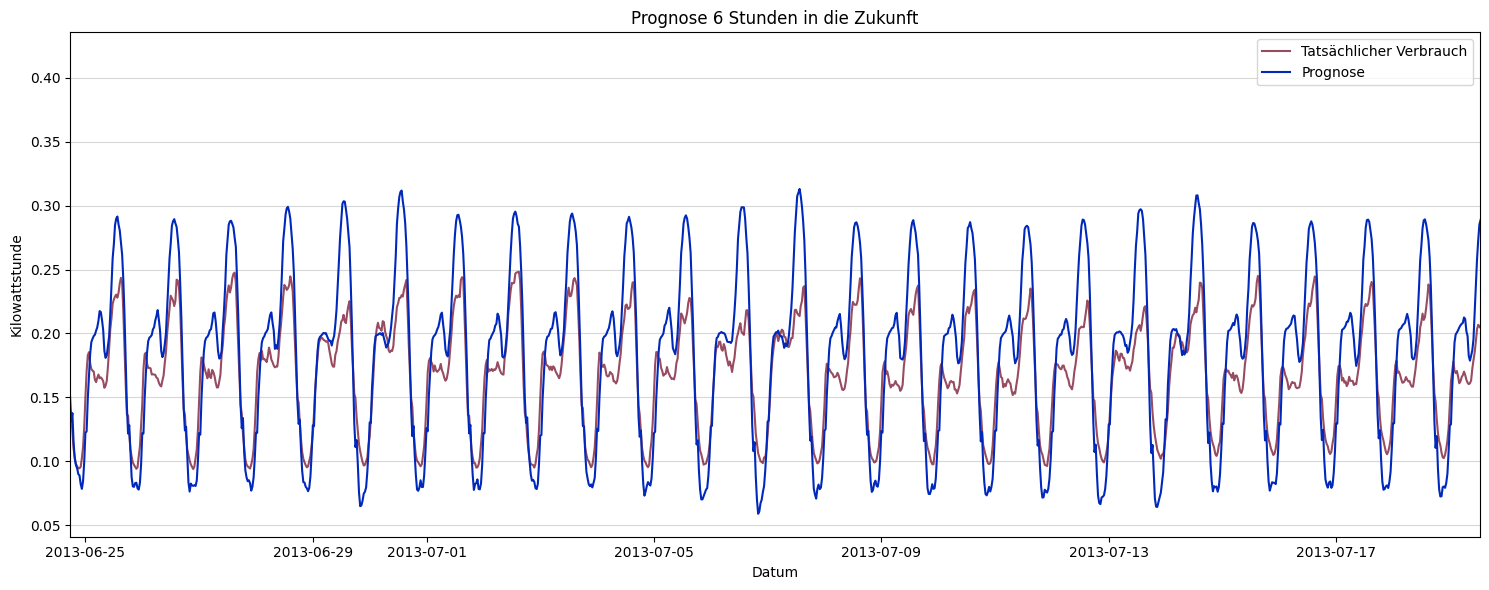

Regression Intercept: -0.00013273513315786856
Regression Coefficients: [ 0.7093596  -0.08036716  1.00052203  0.99978667]
R²:	 0.791968
MSE:	 0.001122
RMSE:	 0.033492
MAE:	 0.027093



In [22]:
# Trainieren des Models
features_a = ["kwh_bereinigt", "kwh_bereinigt_t-1", "kwh_trend", "kwh_saison_t+12"]

X_train_a = train[features_a]
y_train_a = train["kwh_target"]  # Den um 6 Stunden verschobenen Wert nehmen, nicht den Original Wert
model_a = LinearRegression()
model_a.fit(X_train_a, y_train_a)

# Vorhersage auf Testdaten
X_test_a = test[features_a]
y_pred_a = model_a.predict(X_test_a)

plot_pred(test, y_pred_a, "kwh_target")
_ = show_metrics(test["kwh_target"], y_pred_a, model_a)

In [23]:
test["kwh_target"]

date
2013-06-24 17:30:00    0.139908
2013-06-24 18:00:00    0.136840
2013-06-24 18:30:00    0.123115
2013-06-24 19:00:00    0.109820
2013-06-24 19:30:00    0.102670
                         ...   
2014-02-27 16:00:00    0.299760
2014-02-27 16:30:00    0.285163
2014-02-27 17:00:00    0.252274
2014-02-27 17:30:00    0.215284
2014-02-27 18:00:00    0.208997
Freq: 30min, Name: kwh_target, Length: 11906, dtype: float64

<font color="orange">
Erkenntnisse: Das Modell erkennt Saisonalität und Trend gut, hat aber Probleme die Varianz des Residuums genauer einzugrenzen.

Insgesamt liefert das Modell aber gute Prognosen, die nahe der echten Daten liegen.
</font>

---

Als Zielvariable wird nun das Residuum 6 Stunden in der Zukunft verwendet.

Für die eigentliche Vorhersage werden der zuvor berechnete Trend und Saisonalität wieder einberechnet. 

In [24]:
df_model_b = df.copy()
# Train-Test-Split
split = int(len(df_model_b) * 0.7)
train = df_model_b.iloc[:split].copy()
test = df_model_b.iloc[split:].copy()

In [25]:
# Trend
x_train = mdates.date2num(train.index)
p = np.poly1d(np.polyfit(x_train, train["kwh"], 1))

train["kwh_trend"] = p(mdates.date2num(train.index))
test["kwh_trend"] = p(mdates.date2num(test.index))  # Extrapolation

# Trendbereinigung
train["kwh_trendbereinigt"] = train["kwh"] - train["kwh_trend"]
test["kwh_trendbereinigt"] = test["kwh"] - test["kwh_trend"]


# Saisonalität
train["focus"] = train.index.hour * 2 + (train.index.minute // 30)
seasonal = train.groupby("focus")["kwh_trendbereinigt"].mean()

test["focus"] = test.index.hour * 2 + (test.index.minute // 30)

train["kwh_saison"] = train["focus"].map(seasonal)
test["kwh_saison"] = test["focus"].map(seasonal)


# Residuum
train["kwh_bereinigt"] = final_residuals
test["kwh_bereinigt"] = final_residuals


# Aufteilung der Spalten nach Train und Test
for split_df in [train, test]:
    split_df["kwh_bereinigt_t-1"] = split_df["kwh_bereinigt"].shift(1)

    # Trend und Saison bei t+12 – nur für Rekomposition, nicht als Features
    split_df["kwh_trend_t+12"] = split_df["kwh_trend"].shift(-12)
    split_df["kwh_saison_t+12"] = split_df["kwh_saison"].shift(-12)
    # Zielwerte
    split_df["kwh_target_bereinigt"] = split_df["kwh_bereinigt"].shift(-12)
    split_df["kwh_target"] = split_df["kwh"].shift(-12)

last_row = test.iloc[[-1]].copy()


future_time = last_row.index[0] + pd.Timedelta(hours=6)
future_focus = future_time.hour * 2 + (future_time.minute // 30)

last_row["kwh_trend_t+12"] = p(mdates.date2num([future_time]))[0]
last_row["kwh_saison_t+12"] = seasonal.loc[future_focus]

train = train.dropna()
test = test.dropna()

df_model_b = pd.concat([test, last_row])

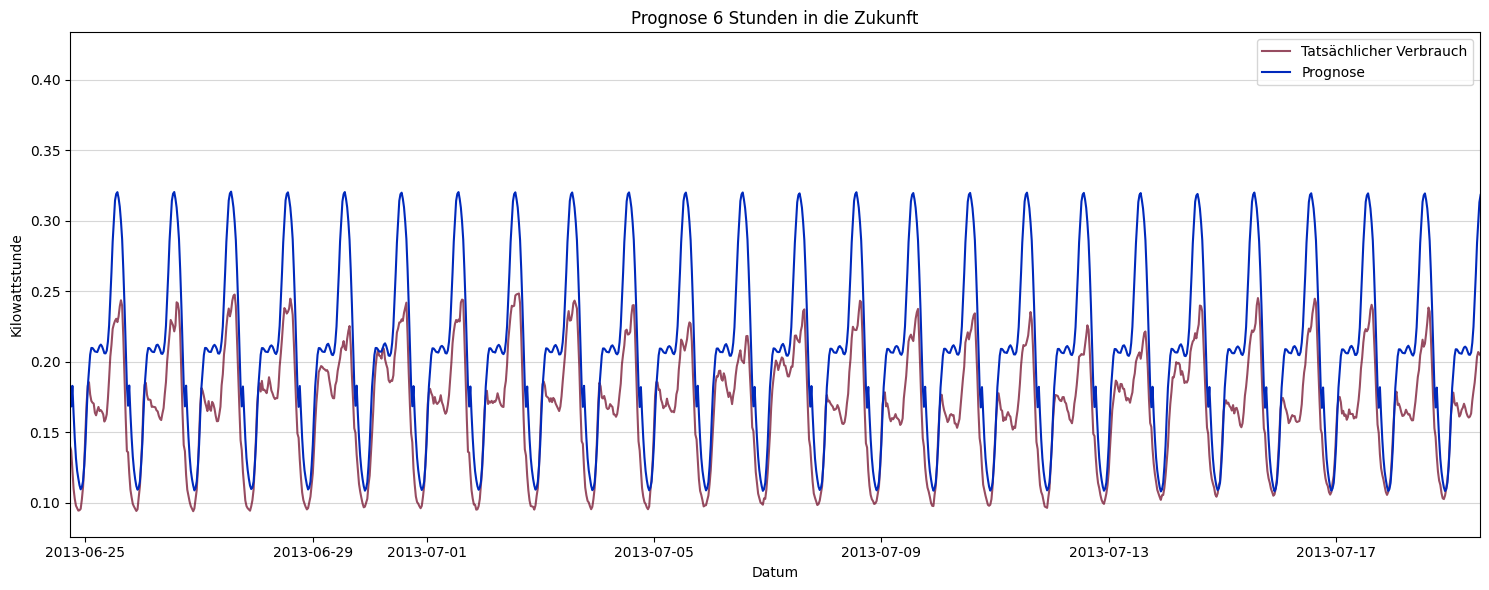

Regression Intercept: -1.531457705696971e-06
Regression Coefficients: [-0.08902897 -0.06055111]
R²:	 0.654624
MSE:	 0.001862
RMSE:	 0.043154
MAE:	 0.035525



In [26]:
features_b = ["kwh_bereinigt", "kwh_bereinigt_t-1"]
# Training (nur Residuum-Lags als Features)
X_train = train[features_b]
y_train = train["kwh_target_bereinigt"]

model_b = LinearRegression()
model_b.fit(X_train, y_train)

# Vorhersage der Testdaten
X_test_b = test[features_b]
y_pred_residuum = model_b.predict(X_test_b)  # Nur das Residuum wird hier vorhergesagt

# Trend und Saisonalität bei t+12 liegen durch .shift(-12) bereits im test-Index vor
y_pred_b = y_pred_residuum + test["kwh_trend_t+12"] + test["kwh_saison_t+12"]

plot_pred(test, y_pred_b, "kwh_target")
_ = show_metrics(test["kwh_target"], y_pred_b, model_b)

<font color="orange">
Erkenntnisse: Das Modell schätzt auch ohne mitgegebenen Trend und Saisonalität das Residuum beinahe exakt gleich ein.

Ein Grund dafür ist durch die PACF gezeigte Abhängigkeit von nur einen Lag. Bei 12 Lags in die Zukunft geht die Abhängigkeit gegen 0 und ist nur noch unerklärbares Rauschen.

Eine Möglichkeit für bessere Ergebnisse wäre z.B. eine feinere Saisonalitätsbestimmung (Unterscheidung zwischen Wochentagen und Wochenenden).
</font>

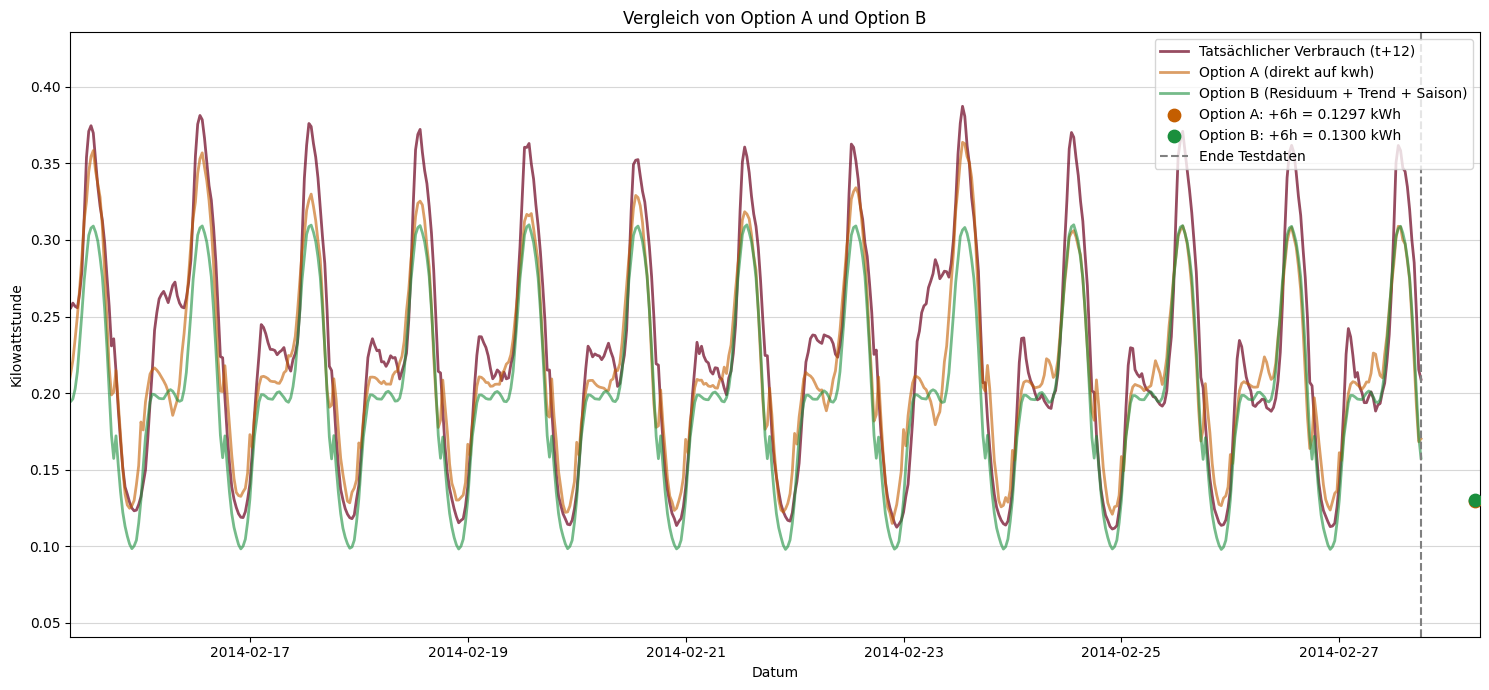

Metrik     Option A   Option B   Verbesserung
---------------------------------------------
R²         0.791968   0.654624      -17.3420%
RMSE       0.033492   0.043154      -28.8488%
MAE        0.027093   0.035525      -31.1230%



In [27]:
# Letzter bekannter Datenpunkt für Zukunftsprognose
last_row_a = df_model_a.iloc[[-1]]
last_row_b = df_model_b.iloc[[-1]]

X_future_a = last_row[features_a]
X_future_b = last_row[features_b]

# Zukunftsprognose Option A
future_pred_a = model_a.predict(X_future_a)[0]
future_time = df_model_a.index[-1] + pd.Timedelta(hours=6)

# Zukunftsprognose Option B
future_residuum_b = model_b.predict(X_future_b)[0]
future_pred_b = future_residuum_b + last_row_b["kwh_trend_t+12"].values[0] + last_row_b["kwh_saison_t+12"].values[0]

_, ax = plt.subplots(figsize=(15, 7))

ax.plot(
    test.index,
    test["kwh_target"],
    color="#6B001E",
    alpha=0.7,
    linewidth=2,
    label="Tatsächlicher Verbrauch (t+12)",
)
ax.plot(test.index, y_pred_a, color="#C45E00", alpha=0.6, linewidth=2, label="Option A (direkt auf kwh)")
ax.plot(test.index, y_pred_b, color="#1A8F3D", alpha=0.6, linewidth=2, label="Option B (Residuum + Trend + Saison)")

ax.scatter(future_time, future_pred_a, color="#C45E00", s=80, zorder=5, label=f"Option A: +6h = {future_pred_a:.4f} kWh")
ax.scatter(future_time, future_pred_b, color="#1A8F3D", s=80, zorder=5, label=f"Option B: +6h = {future_pred_b:.4f} kWh")
ax.axvline(x=test.index[-1], color="gray", linestyle="--", alpha=1, label="Ende Testdaten")

ax.set(
    title="Vergleich von Option A und Option B",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.set_xlim(pd.Series(test.index).quantile(0.95), future_time + pd.Timedelta(hours=1))
ax.grid(axis="y", alpha=0.5)
ax.margins(x=0)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

r2_a, mse_a, rmse_a, mae_a = show_metrics(test["kwh_target"], y_pred_a, model_a, verbose=False)
r2_b, mse_b, rmse_b, mae_b = show_metrics(test["kwh_target"], y_pred_b, model_b, verbose=False)

# Metriken
r2_diff = (r2_b - r2_a) / abs(r2_a) * 100
rmse_diff = (rmse_a - rmse_b) / rmse_a * 100
mae_diff = (mae_a - mae_b) / mae_a * 100

print(
    f"{'Metrik':<8} {'Option A':>10} {'Option B':>10} {'Verbesserung':>14}\n"
    f"{'-' * 45}\n"
    f"{'R²':<8} {r2_a:>10.6f} {r2_b:>10.6f} {r2_diff:>+13.4f}%\n"
    f"{'RMSE':<8} {rmse_a:>10.6f} {rmse_b:>10.6f} {rmse_diff:>+13.4f}%\n"
    f"{'MAE':<8} {mae_a:>10.6f} {mae_b:>10.6f} {mae_diff:>+13.4f}%\n"
)